In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad

from pathlib import Path
from scipy import sparse
from sklearn.cluster import KMeans


In [2]:
from loading import load_data_in_AnnData
H3K27ac_ad, H3K27me3_ad = load_data_in_AnnData()

print("H3K27ac:", H3K27ac_ad.shape)
print("H3K27me3:", H3K27me3_ad.shape)

/home/jeane/miniconda3/envs/MLcourse/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/jeane/miniconda3/envs/MLcourse/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/jeane/miniconda3/envs/MLcourse/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/jeane/miniconda3/envs/MLcourse/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


H3K27ac: (4805, 3782654)
H3K27me3: (4805, 2350516)


In [18]:
from preprocessing import increase_bin_size
factor = 100

filt_H3K27ac = increase_bin_size(H3K27ac_ad, factor=factor)

filt_H3K27me3 = increase_bin_size(H3K27me3_ad, factor=factor)

print("H3K27ac:", filt_H3K27ac.shape)
print("H3K27me3:", filt_H3K27me3.shape)

/home/jeane/miniconda3/envs/MLcourse/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


H3K27ac: (4805, 49815)
H3K27me3: (4805, 48137)


/home/jeane/miniconda3/envs/MLcourse/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [19]:
from preprocessing import prevalence_filtering

threshold = 50

filt_H3K27ac = prevalence_filtering(filt_H3K27ac, threshold=threshold)

filt_H3K27me3 = prevalence_filtering(filt_H3K27me3, threshold=threshold)

print("H3K27ac:", filt_H3K27ac.shape)
print("H3K27me3:", filt_H3K27me3.shape)

Number of bins with more than 50 cells having non-zero values: 42440
Number of bins with more than 50 cells having non-zero values: 26664
H3K27ac: (4805, 42440)
H3K27me3: (4805, 26664)


In [20]:
from labels import group_cell_types


filt_H3K27ac = group_cell_types(filt_H3K27ac)

filt_H3K27me3 = group_cell_types(filt_H3K27me3)

filt_H3K27ac.obs[["cell_type", "cell_type_grouped"]]

/mnt/c/Users/Jeane/Desktop/Learning-Compact-Embeddings-of-Single-Cell-Histone-PTMs/labels.py:18: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[new_key] = pd.Categorical(grouped)


24 classes -> 18 classes (smallest: EXC, 40 cells)


/mnt/c/Users/Jeane/Desktop/Learning-Compact-Embeddings-of-Single-Cell-Histone-PTMs/labels.py:18: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[new_key] = pd.Categorical(grouped)


24 classes -> 18 classes (smallest: EXC, 40 cells)


,cell_type,cell_type_grouped
0,AST_NT,AST_NT
1,MGL1,MGL1
2,AST_TE,AST_TE
3,AST_TE,AST_TE
4,BG,BG
...,...,...
4800,MGL1,MGL1
4801,VEC,VEC
4802,INH4,INH
4803,AST_TE,AST_TE


In [23]:
from spectral import spectral_embedding

n_components = 60

filt_H3K27ac = spectral_embedding(filt_H3K27ac, n_components=n_components, random_state=42)

filt_H3K27me3 = spectral_embedding(filt_H3K27me3, n_components=n_components, random_state=42)

Spectral embedding shape: (4805, 54)
Spectral embedding shape: (4805, 60)


In [24]:
#garder seulement les 50 components

for data in [filt_H3K27ac, filt_H3K27me3]:

    assert data.obsm["X_spectral"].shape[1] >= 50

    data.obsm["X_spectral"] = data.obsm["X_spectral"][:, :50]

    data.uns["spectral_eigenvalue"] = (
        data.uns["spectral_eigenvalue"][:50]
    )

In [25]:
print(filt_H3K27ac)
print(filt_H3K27me3)

print(filt_H3K27ac.obsm["X_spectral"].shape)
print(filt_H3K27me3.obsm["X_spectral"].shape)

AnnData object with n_obs × n_vars = 4805 × 42440
    obs: 'cell_id', 'cell_type', 'sample', 'nCounts_bins_H3K27ac', 'nCounts_bins_H3K27me3', 'cell_type_grouped'
    var: 'chrom', 'start', 'end'
    uns: 'spectral_eigenvalue'
    obsm: 'X_spectral'
AnnData object with n_obs × n_vars = 4805 × 26664
    obs: 'cell_id', 'cell_type', 'sample', 'nCounts_bins_H3K27ac', 'nCounts_bins_H3K27me3', 'cell_type_grouped'
    var: 'chrom', 'start', 'end'
    uns: 'spectral_eigenvalue'
    obsm: 'X_spectral'
(4805, 50)
(4805, 50)


... storing 'cell_type' as categorical
... storing 'sample' as categorical
... storing 'chrom' as categorical


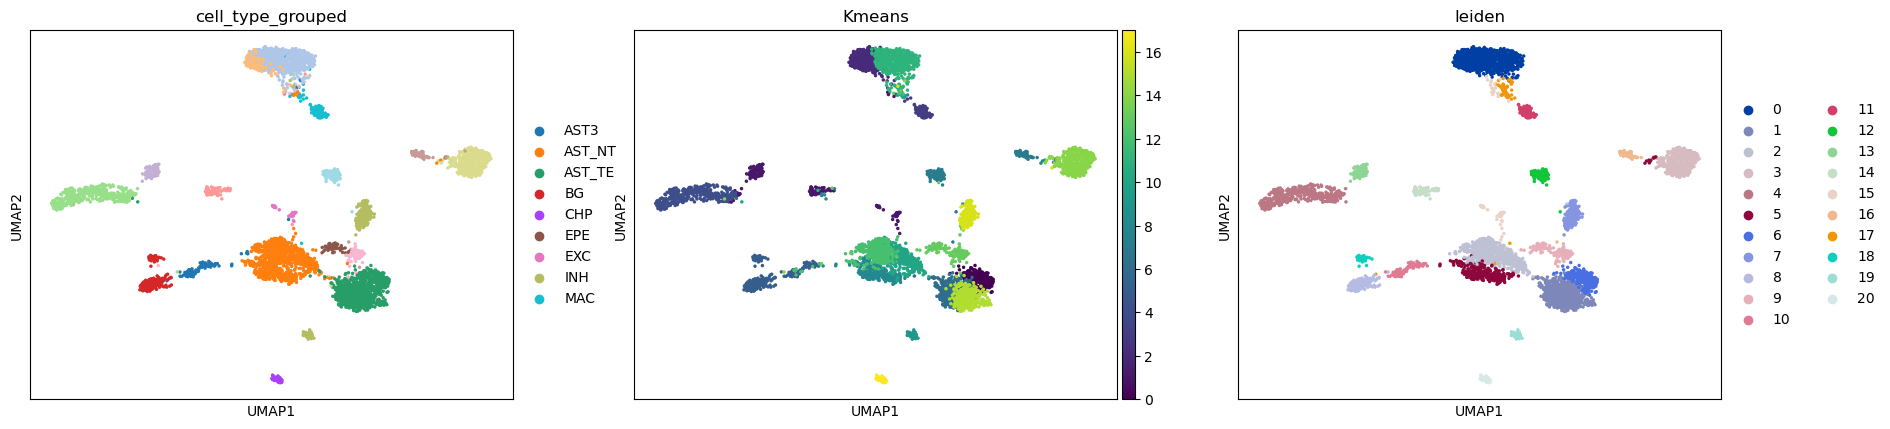

In [26]:
# Clustering me
from clustering import clustering

clustering(
    filt_H3K27me3,
    Kmeans=True,
    leiden=True,
    visualization=True,
    random_state=42,
    type_obs="X_spectral",
    resolution=1,
    cell_type="cell_type_grouped"
)

... storing 'cell_type' as categorical
... storing 'sample' as categorical
... storing 'chrom' as categorical


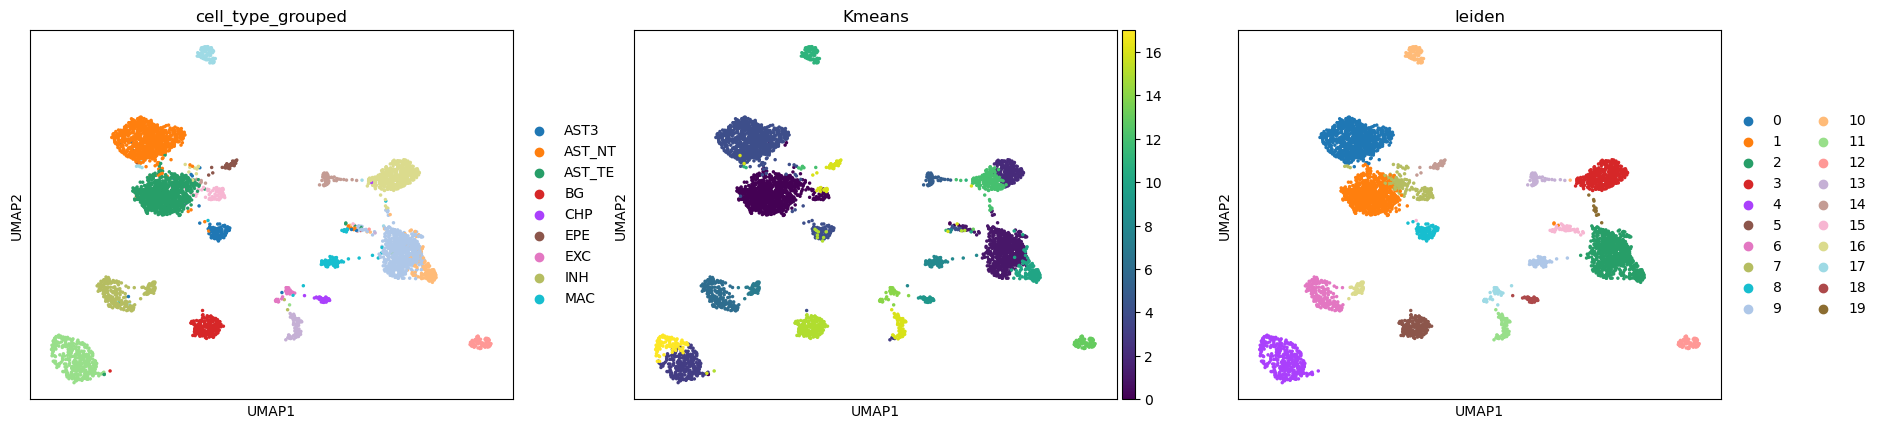

In [27]:
# Clustering ac
from clustering import clustering

clustering(
    filt_H3K27ac,
    Kmeans=True,
    leiden=True,
    visualization=True,
    random_state=42,
    type_obs="X_spectral",
    resolution=1,
    cell_type="cell_type_grouped"
)

In [28]:
from test_clustering import clust_score

print("H3K27me3 - Spectral Embedding\n")

score_me3_kmeans = clust_score(
    filt_H3K27me3,
    nmi_ari=True,
    asw_lisi=True,
    clust_name="Kmeans",
    type_obs="X_spectral",
    cell_type="cell_type_grouped",
    show=True
)

score_me3_leiden = clust_score(
    filt_H3K27me3,
    nmi_ari=True,
    asw_lisi=True,
    clust_name="leiden",
    type_obs="X_spectral",
    cell_type="cell_type_grouped",
    show=True
)

H3K27me3 - Spectral Embedding

Clustering score for Kmeans :
 - NMI score : 0.801, ARI score : 0.574
 - ASW score : 0.573, LISI score (mean) : 1.372
Clustering score for leiden :
 - NMI score : 0.869, ARI score : 0.750
 - ASW score : 0.579, LISI score (mean) : 1.168


In [29]:
print("H3K27ac - Spectral Embedding\n")

score_ac_kmeans = clust_score(
    filt_H3K27ac,
    nmi_ari=True,
    asw_lisi=True,
    clust_name="Kmeans",
    type_obs="X_spectral",
    cell_type="cell_type_grouped",
    show=True
)

score_ac_leiden = clust_score(
    filt_H3K27ac,
    nmi_ari=True,
    asw_lisi=True,
    clust_name="leiden",
    type_obs="X_spectral",
    cell_type="cell_type_grouped",
    show=True
)

H3K27ac - Spectral Embedding

Clustering score for Kmeans :
 - NMI score : 0.887, ARI score : 0.862
 - ASW score : 0.633, LISI score (mean) : 1.106
Clustering score for leiden :
 - NMI score : 0.909, ARI score : 0.888
 - ASW score : 0.641, LISI score (mean) : 1.073


In [31]:
results_spectral = pd.DataFrame(
    [
        score_ac_kmeans,
        score_ac_leiden,
        score_me3_kmeans,
        score_me3_leiden
    ],
    columns=["NMI", "ARI", "ASW", "LISI"],
    index=[
        "H3K27ac - KMeans",
        "H3K27ac - Leiden",
        "H3K27me3 - KMeans",
        "H3K27me3 - Leiden"
    ]
)

display(results_spectral.round(3))

,NMI,ARI,ASW,LISI
H3K27ac - KMeans,0.887,0.862,0.633,1.106
H3K27ac - Leiden,0.909,0.888,0.641,1.073
H3K27me3 - KMeans,0.801,0.574,0.573,1.372
H3K27me3 - Leiden,0.869,0.750,0.579,1.168
